In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
rfm = pd.read_csv(
    "../data/processed/customer_rfm_segmented.csv"
)

print("Customer dataset loaded!")
print("Rows:", len(rfm))
print("Columns:", len(rfm.columns))

Customer dataset loaded!
Rows: 4312
Columns: 9


In [3]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,12346.0,164,11,372.86,2,5,2,252,At Risk
1,12347.0,2,2,1323.32,5,2,4,524,Potential Loyalists
2,12348.0,73,1,222.16,2,1,1,211,Needs Attention
3,12349.0,42,3,2671.14,3,3,5,335,Needs Attention
4,12351.0,10,1,300.93,5,1,2,512,Needs Attention


In [4]:
df = pd.read_csv(
    "../data/processed/cleaned_transactions.csv"
)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [5]:
quantity_features = (
    df.groupby("Customer ID")["Quantity"]
    .sum()
    .rename("Total_Quantity")
)

In [6]:
product_features = (
    df.groupby("Customer ID")["StockCode"]
    .nunique()
    .rename("Unique_Products")
)

In [7]:
order_features = (
    df.groupby("Customer ID")
    .agg(
        Average_Order_Value=("Revenue", "mean"),
        Total_Orders=("Invoice", "nunique")
    )
)

In [8]:
ml_data = rfm.merge(
    quantity_features,
    on="Customer ID",
    how="left"
)

ml_data = ml_data.merge(
    product_features,
    on="Customer ID",
    how="left"
)

ml_data = ml_data.merge(
    order_features,
    on="Customer ID",
    how="left"
)

In [9]:
ml_data.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment,Total_Quantity,Unique_Products,Average_Order_Value,Total_Orders
0,12346.0,164,11,372.86,2,5,2,252,At Risk,70,26,11.298788,11
1,12347.0,2,2,1323.32,5,2,4,524,Potential Loyalists,828,70,18.638310,2
2,12348.0,73,1,222.16,2,1,1,211,Needs Attention,373,20,11.108000,1
3,12349.0,42,3,2671.14,3,3,5,335,Needs Attention,993,90,26.187647,3
4,12351.0,10,1,300.93,5,1,2,512,Needs Attention,261,21,14.330000,1


In [10]:
ml_data.shape

(4312, 13)

In [11]:
high_value_threshold = ml_data["Monetary"].quantile(0.75)

print(
    "High-value customer threshold:",
    round(high_value_threshold, 2)
)

High-value customer threshold: 1714.93


In [12]:
ml_data["High_Value"] = (
    ml_data["Monetary"] >= high_value_threshold
).astype(int)

In [13]:
ml_data["High_Value"].value_counts()

High_Value
0    3234
1    1078
Name: count, dtype: int64

In [14]:
ml_data["High_Value"].value_counts(normalize=True) * 100

High_Value
0    75.0
1    25.0
Name: proportion, dtype: float64

In [15]:
features = [
    "Recency",
    "Frequency",
    "Total_Quantity",
    "Unique_Products",
    "Average_Order_Value",
    "Total_Orders"
]

X = ml_data[features]
y = ml_data["High_Value"]

In [16]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4312, 6)
y shape: (4312,)


In [17]:
print("Missing values:")
print(X.isnull().sum())

Missing values:
Recency                0
Frequency              0
Total_Quantity         0
Unique_Products        0
Average_Order_Value    0
Total_Orders           0
dtype: int64


In [18]:
X = X.fillna(X.median())

In [19]:
print("Remaining missing values:", X.isnull().sum().sum())

Remaining missing values: 0


In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [22]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3449
Testing samples: 863


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [26]:
from sklearn.linear_model import LogisticRegression

In [27]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [28]:
logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [29]:
logistic_predictions = logistic_model.predict(
    X_test_scaled
)

In [30]:
from sklearn.ensemble import RandomForestClassifier

In [31]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [32]:
rf_model.fit(
    X_train,
    y_train
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [33]:
rf_predictions = rf_model.predict(X_test)

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [35]:
def evaluate_model(name, y_true, predictions, probabilities):
    
    accuracy = accuracy_score(y_true, predictions)
    precision = precision_score(y_true, predictions)
    recall = recall_score(y_true, predictions)
    f1 = f1_score(y_true, predictions)
    roc_auc = roc_auc_score(y_true, probabilities)
    
    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "ROC_AUC": roc_auc
    }

In [36]:
logistic_probabilities = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

In [37]:
rf_probabilities = rf_model.predict_proba(
    X_test
)[:, 1]

In [38]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_predictions,
        logistic_probabilities
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions,
        rf_probabilities
    )
)

model_results = pd.DataFrame(results)

model_results

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.915411,0.882353,0.763889,0.818859,0.972215
1,Random Forest,0.936269,0.888889,0.851852,0.869976,0.986308


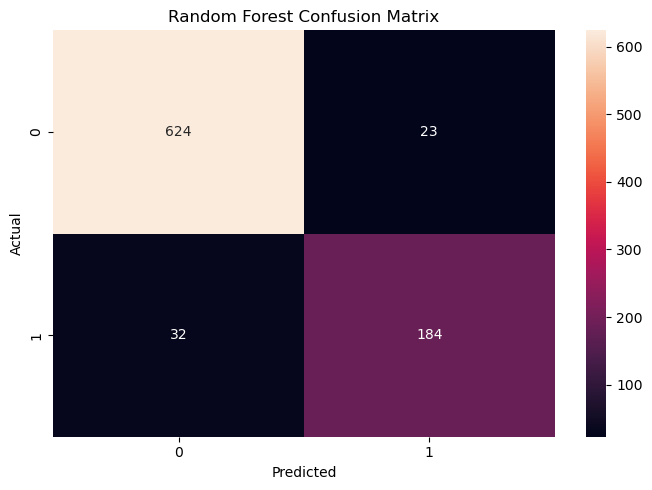

In [39]:
cm = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    "../charts/random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,Total_Quantity,0.393797
5,Total_Orders,0.168260
1,Frequency,0.150905
3,Unique_Products,0.139747
4,Average_Order_Value,0.106414
0,Recency,0.040876


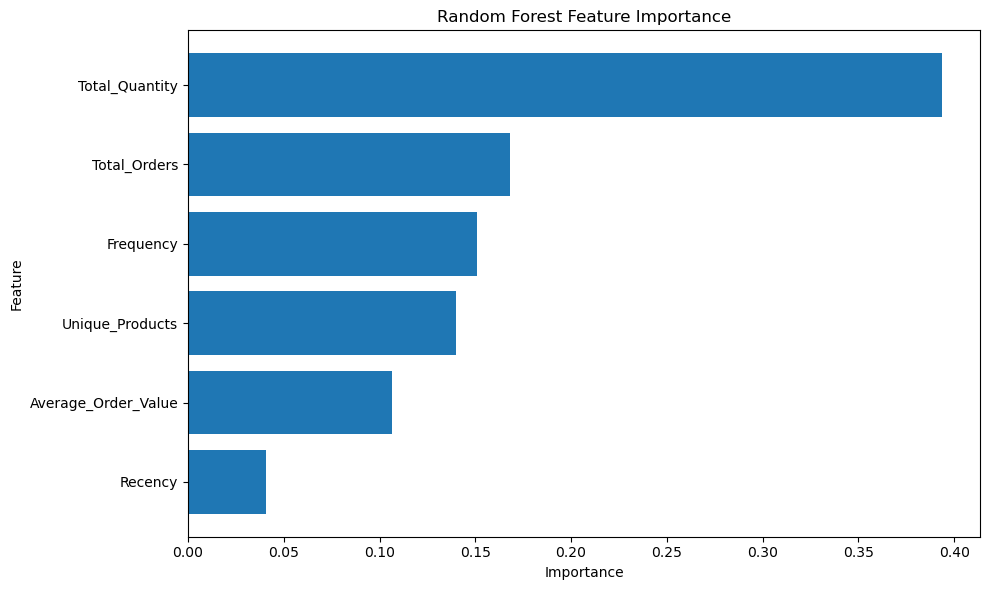

In [41]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "../charts/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
model_results.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "../reports/feature_importance.csv",
    index=False
)

print("Model results saved successfully!")

Model results saved successfully!


In [43]:
import joblib

In [44]:
joblib.dump(
    rf_model,
    "../models/random_forest_customer_model.pkl"
)

joblib.dump(
    scaler,
    "../models/customer_feature_scaler.pkl"
)

print("Models saved successfully!")

Models saved successfully!


In [1]:
print("High-Value Class Distribution:")
print(ml_data["High_Value"].value_counts())

print("\nPercentage Distribution:")
print(
    ml_data["High_Value"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

High-Value Class Distribution:


NameError: name 'ml_data' is not defined

In [2]:
import pandas as pd

# Load segmented customer data
rfm = pd.read_csv(
    "../data/processed/customer_rfm_segmented.csv"
)

# Load customer summary
customer_summary = pd.read_csv(
    "../data/processed/customer_summary.csv"
)

# Check column names
print("RFM columns:")
print(rfm.columns.tolist())

print("\nCustomer summary columns:")
print(customer_summary.columns.tolist())

RFM columns:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Customer_Segment']

Customer summary columns:
['Customer ID', 'Total_Revenue', 'Total_Quantity', 'Total_Orders', 'Average_Order_Value', 'Unique_Products']


In [3]:
# Rename Customer ID if necessary

rfm.rename(
    columns={"Customer ID": "CustomerID"},
    inplace=True
)

customer_summary.rename(
    columns={"Customer ID": "CustomerID"},
    inplace=True
)

# Merge customer data
ml_data = rfm.merge(
    customer_summary,
    on="CustomerID",
    how="left"
)

print("ML dataset created!")
print("Rows:", len(ml_data))
print("Columns:", len(ml_data.columns))

print("\nML columns:")
print(ml_data.columns.tolist())

ML dataset created!
Rows: 4312
Columns: 14

ML columns:
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Customer_Segment', 'Total_Revenue', 'Total_Quantity', 'Total_Orders', 'Average_Order_Value', 'Unique_Products']


In [4]:
# Define high-value customer threshold

high_value_threshold = ml_data["Monetary"].quantile(0.75)

print("High-value threshold:", high_value_threshold)

# Create target
ml_data["High_Value"] = (
    ml_data["Monetary"] >= high_value_threshold
).astype(int)

print("\nHigh-Value target created!")
print(ml_data["High_Value"].value_counts())

High-value threshold: 1714.9325000000001

High-Value target created!
High_Value
0    3234
1    1078
Name: count, dtype: int64


In [5]:
print("High-Value Class Distribution:")
print(ml_data["High_Value"].value_counts())

print("\nPercentage Distribution:")
print(
    ml_data["High_Value"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

High-Value Class Distribution:
High_Value
0    3234
1    1078
Name: count, dtype: int64

Percentage Distribution:
High_Value
0    75.0
1    25.0
Name: proportion, dtype: float64


In [6]:
features = [
    "Recency",
    "Frequency",
    "Total_Quantity",
    "Unique_Products",
    "Average_Order_Value",
    "Total_Orders"
]

X = ml_data[features]
y = ml_data["High_Value"]

print("Features:")
print(features)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['Recency', 'Frequency', 'Total_Quantity', 'Unique_Products', 'Average_Order_Value', 'Total_Orders']

X shape: (4312, 6)
y shape: (4312,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training rows: 3449
Testing rows: 863

Training class distribution:
High_Value
0    2587
1     862
Name: count, dtype: int64

Testing class distribution:
High_Value
0    647
1    216
Name: count, dtype: int64


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Feature scaling completed!
Training shape: (3449, 6)
Testing shape: (863, 6)


In [9]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

print("Random Forest model created!")

Random Forest model created!


In [10]:
rf_model.fit(
    X_train_scaled,
    y_train
)

print("Random Forest training completed!")

Random Forest training completed!


In [11]:
y_pred = rf_model.predict(X_test_scaled)

y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated!")

print("\nPredicted class distribution:")
print(pd.Series(y_pred).value_counts())

print("\nProbability range:")
print("Minimum:", round(y_prob.min(), 4))
print("Maximum:", round(y_prob.max(), 4))
print("Average:", round(y_prob.mean(), 4))

Predictions generated!

Predicted class distribution:
0    658
1    205
Name: count, dtype: int64

Probability range:
Minimum: 0.0
Maximum: 1.0
Average: 0.2359


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print("Random Forest Performance")
print("-------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Random Forest Performance
-------------------------
Accuracy : 0.934
Precision: 0.8878
Recall   : 0.8426
F1 Score : 0.8646
ROC-AUC  : 0.9862


In [13]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96       647
           1       0.89      0.84      0.86       216

    accuracy                           0.93       863
   macro avg       0.92      0.90      0.91       863
weighted avg       0.93      0.93      0.93       863



In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[624  23]
 [ 34 182]]


In [15]:
import joblib

joblib.dump(
    rf_model,
    "../models/random_forest_customer_model.pkl"
)

joblib.dump(
    scaler,
    "../models/customer_feature_scaler.pkl"
)

print("Fixed Random Forest model saved!")
print("Fixed scaler saved!")

Fixed Random Forest model saved!
Fixed scaler saved!
